# Does the choice of band change the counts?

Every sample can have three bands, each 300 µm deep on one side of a junction line:

- **first** — the first annotator's hand-drawn line and band;
- **second** — Quillan's hand-drawn line and band (most samples);
- **automatic** — the junction finder's line, with the same band width (missing where the finder found nothing).

The cells were segmented once over the whole section, so the three bands count **the same cells**; only which of them are inside, and where the line runs, differs. This notebook asks whether that difference matters for the AF488 counts, under four positivity rules:

| rule | a cell is positive when |
|---|---|
| median + 3 SD (current) | brighter than median + 3 SD of the band's own cells (what the junction analysis does now) |
| median + 7 SD, filtered | the same with k = 7, on the channel less its local median (slow haze removed) |
| negative 99.9th pct | brighter than 99.9 % of the negative control: cells more than 300 µm deep in the organoid where AF488 is not at home |
| contrast, no autofl. | brighter against its own ring than 99 % of the negative control's cells are, and not as bright (for its ring) in AF555 — that would be autofluorescence |

The first two take their threshold from the band itself, so the band changes the threshold as well as which cells are counted. The last two take it from the negative control, which is placed from the band's line.

Two numbers per band: **% positive** (positives over all cells in the band) and **positives per mm** of that band's line (the line length differs between bands, so this is per mm of each band's own line).

Sections: (1) how many cells the bands share; (2) how far the counts move between bands; (3) the same, split by the finder's triage; (4) the band's shape: 150 against 300 µm deep, and the positives at the tissue edge; (5) whether the genotype comparison changes with the band.

In [1]:
import warnings
from pathlib import PureWindowsPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import count_common as C

cells, meta = C.load_all()
LABEL = C.label_channel(meta)
CHANNELS = meta["channels"].iloc[0]

ALL_RULES = C.rules(CHANNELS, LABEL)
RULES = {name: ALL_RULES[name] for name in [
    "band median + 3 SD (current)",
    "band median + 7 SD, median filter",
    "negative control 99.9th pct",
    "ring contrast > negative 99th pct, no autofluorescence",
]}
SHORT = dict(zip(RULES, ["median + 3 SD (current)", "median + 7 SD, filtered", "negative 99.9th pct",
                         "contrast, no autofl."]))
COLOURS = {"WT3": "tab:blue", "GD1": "tab:orange", "WT2": "tab:green"}
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)


def tidy(table, digits=2):
    # For display: numbers rounded, p values in scientific notation, columns of numbers stored as text made numeric.
    out = table.copy()
    for c in out.columns:
        values = pd.to_numeric(out[c], errors="coerce")
        if values.notna().sum() < out[c].notna().sum():
            continue
        if str(c).startswith("p ") or str(c).endswith(" p") or str(c).startswith("p ("):
            out[c] = [f"{v:.1e}" if np.isfinite(v) else "" for v in values]
        else:
            out[c] = values.astype(float).round(digits)
    return out


print(f"label channel {LABEL} (all channels {CHANNELS}); genotypes {meta['Genotype'].value_counts().to_dict()}")

PAIRS = [("first", "second"), ("first", "automatic"), ("second", "automatic")]

30 of 30 annotated samples measured, 919,868 cells; bands: first 30, second 27, automatic 26
label channel AF488 (all channels ['AF555', 'AF488']); genotypes {'GD1': 19, 'WT3': 11}


## The counts

Each rule is run once per sample and band (the threshold of the band rules comes from that band's cells; the negative control is placed from that band's line). Below: the median over samples, per rule and band. Where a sample has fewer than 50 negative-control cells 300 µm past the line, the negative-control rules move the control nearer (200, then 100 µm), and call nothing if that fails (a warning is printed).

In [2]:
calls, rows = {}, []
for name, df in cells.items():
    for band in meta.loc[name, "bands"]:
        inside = df[f"in {band}"].to_numpy()
        length_mm = meta.loc[name, "lengths (um)"][band] / 1000
        for rule, f in RULES.items():
            positive = np.asarray(f(df, band), bool)
            calls[name, band, rule] = positive
            n = int((positive & inside).sum())
            rows.append({"name": name, "band": band, "rule": rule, "cells": int(inside.sum()), "positive": n,
                         "%": 100 * n / inside.sum() if inside.any() else np.nan,
                         "per mm": n / length_mm if length_mm else np.nan})
counts = pd.DataFrame(rows)
counts = counts.join(meta[["Genotype", "slide"]], on="name")
print("samples per band:", counts.groupby("band")["name"].nunique().reindex(C.BANDS).fillna(0).astype(int).to_dict())
(counts.pivot_table(index="rule", columns="band", values=["cells", "%", "per mm"], aggfunc="median")
 .reindex(columns=C.BANDS, level=1).rename(index=SHORT).round(1))

samples per band: {'first': 30, 'second': 27, 'automatic': 26}


%                    cells                   per mm                 
band                    first second automatic   first  second automatic  first second automatic
rule                                                                                            
median + 3 SD (current)   1.5    1.6       2.0  5209.5  5785.0    5299.0   85.1   92.4     128.9
median + 7 SD, filtered   0.3    0.3       0.2  5209.5  5785.0    5299.0   11.8   13.4      16.5
negative 99.9th pct       0.4    1.0       0.6  5209.5  5785.0    5299.0   25.5   35.0      36.2
contrast, no autofl.      1.0    1.2       1.0  5209.5  5785.0    5299.0   53.3   49.8      60.2

## 1. How many cells the bands share

For each pair of bands, of the cells in either band, the share that is in both (**Jaccard index**): 1 when the two bands hold exactly the same cells, 0 when they do not overlap at all. A low value means the two bands sit in different places (another stretch of the junction, or the other side of it); a value around 0.8–0.9 means the same place with edges a few cells apart.

In [3]:
def jaccard(df, a, b):
    in_a, in_b = df[f"in {a}"].to_numpy(), df[f"in {b}"].to_numpy()
    union = (in_a | in_b).sum()
    return (in_a & in_b).sum() / union if union else np.nan


overlap = pd.DataFrame({f"{a}–{b}": pd.Series({C.short(n): jaccard(df, a, b) for n, df in cells.items()
                                               if f"in {a}" in df and f"in {b}" in df}, dtype=float)
                        for a, b in PAIRS})
summary = pd.DataFrame({"median": overlap.median(), "lowest": overlap.min(), "n": overlap.count()}).T
display(pd.concat([overlap, summary]).round(2))

,first–second,first–automatic,second–automatic
019-018_s10,0.90,0.67,0.64
020-019_s4,0.92,0.85,0.80
026-025_s4,0.94,0.88,0.87
026-025_s8,0.96,0.84,0.87
027-026_s5,0.96,0.72,0.72
031-030_s7,0.78,0.81,0.90
033-032_s12,0.97,0.01,0.01
034-033_s13,0.91,0.95,0.88
034-033_s17,0.87,0.28,0.26
034-033_s3,0.92,0.89,0.93


## 2. How far the counts move between bands

For each rule and each pair of bands, per sample: the second band's value minus the first's (**difference**, in percentage points for % positive, in cells per mm for positives per mm), its mean over samples (a bias: one band systematically counting more), its SD and the **95 % limits of agreement** (mean ± 1.96 SD: the range within which the difference falls for most samples). **CCC** (Lin's concordance) is 1 when the two bands give exactly the same number on every sample; **Spearman** only asks whether they rank the samples the same way.

**How to read the figure** (Bland-Altman, % positive): one panel per rule (rows) and pair of bands (columns); one dot per sample, at the mean of the two bands (x) and their difference (y). The solid line is the mean difference, dashed the 95 % limits. Dots spread along y mean the band matters; a cloud off zero means a bias; a funnel widening to the right means the difference grows with the count.

In [4]:
def pair_table(frame, metric):
    out = []
    for rule in RULES:
        wide = frame[frame["rule"] == rule].pivot_table(index="name", columns="band", values=metric)
        for a, b in PAIRS:
            if a not in wide or b not in wide:
                continue
            g = wide[[a, b]].dropna()
            if len(g) < 2:
                continue
            d = g[b] - g[a]
            out.append({"rule": SHORT[rule], "pair": f"{b} − {a}", "n": len(g),
                        "median a": g[a].median(), "median b": g[b].median(),
                        "difference, mean": d.mean(), "difference, SD": d.std(),
                        "|difference|, median": d.abs().median(),
                        "95% limits": f"{d.mean() - 1.96 * d.std():.1f} to {d.mean() + 1.96 * d.std():.1f}",
                        "CCC": C.ccc(g[a], g[b]), "Spearman": stats.spearmanr(g[a], g[b]).statistic})
    return pd.DataFrame(out)


for metric, unit in (("%", "pp"), ("per mm", "cells per mm")):
    print(f"{metric} positive in the band; differences in {unit}; a = the first band of the pair, b = the second")
    t = pair_table(counts, metric)
    display(t.round(2) if len(t) else "no pair of bands on two or more samples")

% positive in the band; differences in pp; a = the first band of the pair, b = the second


,rule,pair,n,median a,median b,"difference, mean","difference, SD","|difference|, median",95% limits,CCC,Spearman
0,median + 3 SD (current),second − first,27,1.61,1.64,-0.17,0.85,0.10,-1.8 to 1.5,0.97,0.96
1,median + 3 SD (current),automatic − first,26,1.76,1.99,-0.45,2.49,0.34,-5.3 to 4.4,0.73,0.89
2,median + 3 SD (current),automatic − second,25,1.64,1.87,-0.26,1.84,0.29,-3.9 to 3.3,0.84,0.90
3,"median + 7 SD, filtered",second − first,27,0.34,0.28,0.04,0.43,0.03,-0.8 to 0.9,0.63,0.81
4,"median + 7 SD, filtered",automatic − first,26,0.38,0.25,-0.05,0.24,0.09,-0.5 to 0.4,0.90,0.79
5,"median + 7 SD, filtered",automatic − second,25,0.28,0.23,-0.02,0.21,0.03,-0.4 to 0.4,0.89,0.81
6,negative 99.9th pct,second − first,27,0.44,1.04,0.00,0.85,0.23,-1.7 to 1.7,0.98,0.77
7,negative 99.9th pct,automatic − first,26,0.57,0.58,-0.18,2.16,0.32,-4.4 to 4.1,0.86,0.69
8,negative 99.9th pct,automatic − second,25,1.16,0.51,-0.11,2.48,0.09,-5.0 to 4.7,0.82,0.71
9,"contrast, no autofl.",second − first,27,1.05,1.25,0.00,0.77,0.11,-1.5 to 1.5,0.75,0.75


per mm positive in the band; differences in cells per mm; a = the first band of the pair, b = the second


,rule,pair,n,median a,median b,"difference, mean","difference, SD","|difference|, median",95% limits,CCC,Spearman
0,median + 3 SD (current),second − first,27,93.98,92.37,-16.23,48.10,4.42,-110.5 to 78.1,0.96,0.98
1,median + 3 SD (current),automatic − first,26,91.10,128.93,48.12,162.71,33.58,-270.8 to 367.0,0.67,0.75
2,median + 3 SD (current),automatic − second,25,92.37,129.90,66.17,155.34,30.76,-238.3 to 370.6,0.65,0.78
3,"median + 7 SD, filtered",second − first,27,12.63,13.44,-3.06,8.51,1.94,-19.7 to 13.6,0.95,0.84
4,"median + 7 SD, filtered",automatic − first,26,17.67,16.54,11.30,34.25,7.52,-55.8 to 78.4,0.61,0.79
5,"median + 7 SD, filtered",automatic − second,25,13.44,15.50,14.51,34.25,4.49,-52.6 to 81.6,0.56,0.85
6,negative 99.9th pct,second − first,27,26.20,35.00,-16.62,71.30,7.36,-156.4 to 123.1,0.91,0.81
7,negative 99.9th pct,automatic − first,26,28.56,36.21,239.43,1021.06,22.29,-1761.8 to 2240.7,0.13,0.71
8,negative 99.9th pct,automatic − second,25,47.15,36.88,268.14,1080.39,14.96,-1849.4 to 2385.7,0.05,0.71
9,"contrast, no autofl.",second − first,27,56.37,49.81,-6.98,20.94,6.56,-48.0 to 34.1,0.95,0.86


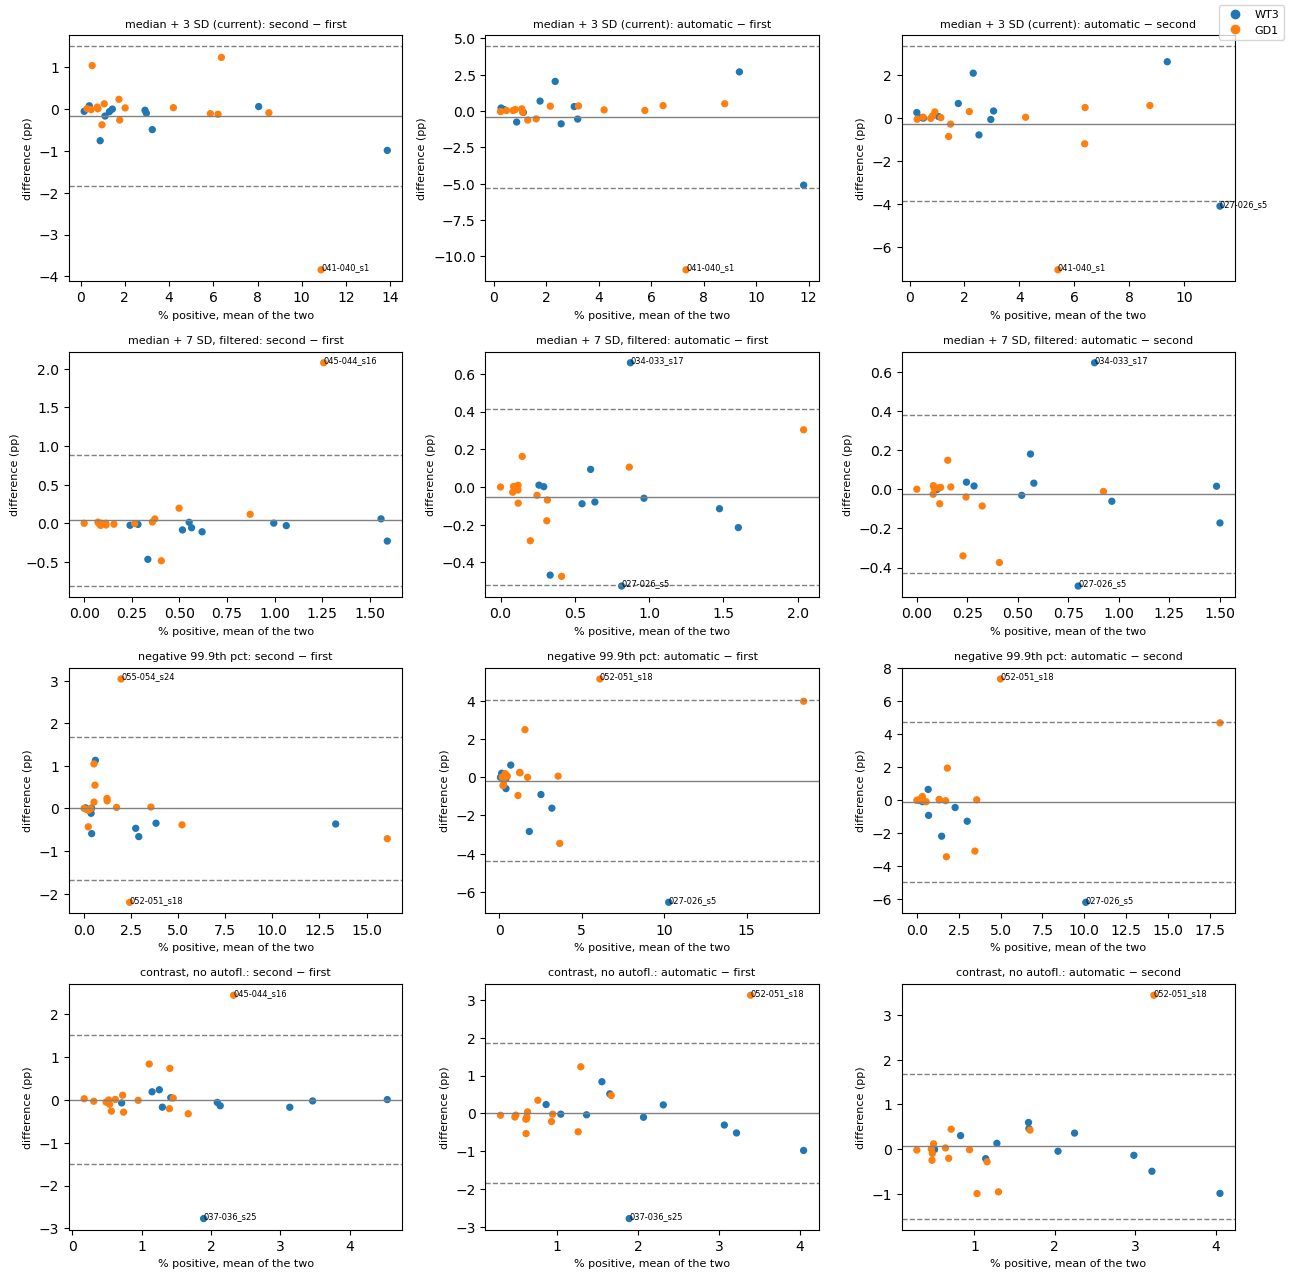

In [5]:
fig, axes = plt.subplots(len(RULES), len(PAIRS), figsize=(4.3 * len(PAIRS), 3.2 * len(RULES)), squeeze=False)
for row, rule in zip(axes, RULES):
    wide = counts[counts["rule"] == rule].pivot_table(index="name", columns="band", values="%")
    for ax, (a, b) in zip(row, PAIRS):
        ax.set_title(f"{SHORT[rule]}: {b} − {a}", fontsize=8)
        if a not in wide or b not in wide or wide[[a, b]].dropna().shape[0] < 2:
            ax.text(0.5, 0.5, "fewer than 2 samples", ha="center", transform=ax.transAxes, fontsize=8)
            continue
        g = wide[[a, b]].dropna()
        mean, diff = g.mean(axis=1), g[b] - g[a]
        ax.scatter(mean, diff, s=18, c=[COLOURS.get(meta.loc[n, "Genotype"], "grey") for n in g.index])
        for y, style in ((diff.mean(), "-"), (diff.mean() - 1.96 * diff.std(), "--"), (diff.mean() + 1.96 * diff.std(), "--")):
            ax.axhline(y, color="grey", ls=style, lw=1)
        for n, x, y in zip(g.index, mean, diff):
            if len(g) > 3 and abs(y - diff.mean()) > 1.96 * diff.std():
                ax.annotate(C.short(n), (x, y), fontsize=6)
        ax.set_xlabel("% positive, mean of the two", fontsize=8)
        ax.set_ylabel("difference (pp)", fontsize=8)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in COLOURS.items() if g in set(meta["Genotype"])]
fig.legend(handles=handles, loc="upper right", fontsize=8)
plt.tight_layout()

## 3. The finder's triage

The junction finder screens itself: a sample whose automatic result is **"fail"** (`scores.csv`, variant `bend 1000`), or whose prescreen shape is **"Damaged"** (the picks table), is routed to be drawn by hand; the others are **kept** with the automatic band. If the triage works, the automatic band should agree with the hand-drawn ones on the kept samples about as well as the two hand-drawn bands agree with each other, and the large disagreements should sit among the routed samples. A sample missing from `scores.csv` is marked "not scored" and left out of both groups.

**How to read it:** the same table as in section 2, once for the kept and once for the routed samples. Compare the first–automatic and second–automatic rows of the kept samples with the first–second row: if they are close, the automatic band can stand in for a hand-drawn one where the triage keeps it.

In [6]:
scores = pd.read_csv(C.OUT / "scores.csv")
status = scores[scores["variant"] == "bend 1000"].drop_duplicates("name").set_index("name")["status"]
picks = pd.read_csv(C.jt.PICKS, encoding="utf-8-sig")
picks["name"] = [PureWindowsPath(str(p)).name.replace(".ome.tiff", "") for p in picks["path"]]
shape = picks.drop_duplicates("name").set_index("name")["Shape"]

triage = pd.DataFrame({"status": status.reindex(list(cells)), "Shape": shape.reindex(list(cells))}, index=list(cells))
routed = triage["status"].eq("fail") | triage["Shape"].eq("Damaged")
triage["route"] = np.where(routed, "routed", np.where(triage["status"].isna(), "not scored", "kept"))
triage["automatic band"] = ["automatic" in meta.loc[n, "bands"] for n in triage.index]
print("samples:", triage["route"].value_counts().to_dict())
print("with an automatic band:", triage.groupby("route")["automatic band"].sum().astype(int).to_dict())
display(triage[triage["route"] != "kept"].rename(index=C.short))

samples: {'kept': 23, 'routed': 7}
with an automatic band: {'kept': 23, 'routed': 3}


,status,Shape,route,automatic band
052-051_s14,fail,Fused pair,routed,False
044-043_s19,fail,Damaged,routed,False
045-044_s16,fail,Damaged,routed,False
033-032_s12,check,Damaged,routed,True
037-036_s25,check,Damaged,routed,True
041-040_s1,check,Damaged,routed,True
052-051_s23,fail,Fused pair,routed,False


In [7]:
COMPACT = ["rule", "pair", "n", "difference, mean", "difference, SD", "|difference|, median", "CCC", "Spearman"]
for metric in ("%", "per mm"):
    parts = {}
    for route in ("kept", "routed"):
        names = triage.index[triage["route"] == route]
        t = pair_table(counts[counts["name"].isin(names)], metric)
        if len(t):
            parts[route] = t[COMPACT].set_index(["rule", "pair"])
    print(f"{metric} positive, by triage group")
    display(pd.concat(parts, names=["group"]).round(2) if parts else "no group with a pair of bands on two or more samples")

% positive, by triage group


n  difference, mean  difference, SD  |difference|, median   CCC  Spearman
group  rule                    pair                                                                                          
kept   median + 3 SD (current) second − first      22             -0.04            0.38                  0.08  0.99      0.99
                               automatic − first   23             -0.03            1.35                  0.30  0.92      0.96
                               automatic − second  22             -0.01            1.24                  0.29  0.93      0.95
       median + 7 SD, filtered second − first      22             -0.03            0.13                  0.02  0.96      0.93
                               automatic − first   23             -0.03            0.23                  0.09  0.91      0.86
                               automatic − second  22             -0.01            0.21                  0.03  0.89      0.86
       negative 99.9th pct     second − first      22             -0.00            0.91                  0.21  0.98      0.82
                               automatic − first   23             -0.02            2.18                  0.26  0.87      0.72
                               automatic − second  22              0.02            2.56                  0.16  0.83      0.68
       contrast, no autofl.    second − first      22              0.02            0.29                  0.12  0.96      0.87
                               automatic − first   23              0.10            0.80                  0.22  0.75      0.86
                               automatic − second  22              0.03            0.87                  0.23  0.71      0.82
routed median + 3 SD (current) second − first       5             -0.73            1.86                  0.75  0.90      0.90
                               automatic − first    3             -3.67            6.33                  0.76  0.07      0.50
                               automatic − second   3             -2.14            4.30                  0.68  0.13      0.50
       median + 7 SD, filtered second − first       5              0.33            1.00                  0.06 -0.00      0.30
                               automatic − first    3             -0.27            0.20                  0.28  0.67      1.00
                               automatic − second   3             -0.13            0.18                  0.06  0.88      0.50
       negative 99.9th pct     second − first       5              0.01            0.63                  0.39  0.96      0.46
                               automatic − first    3             -1.38            1.83                  0.59  0.47      0.50
                               automatic − second   3             -1.05            1.76                  0.08  0.54      1.00
       contrast, no autofl.    second − first       5             -0.07            1.85                  0.10 -0.02      0.60
                               automatic − first    3             -0.64            1.85                  0.52 -0.33     -0.50
                               automatic − second   3              0.30            0.27                  0.45  0.78      0.50

per mm positive, by triage group


n  difference, mean  difference, SD  |difference|, median   CCC  Spearman
group  rule                    pair                                                                                          
kept   median + 3 SD (current) second − first      22            -14.33           49.36                  4.16  0.95      0.99
                               automatic − first   23             62.24          150.29                 31.90  0.72      0.83
                               automatic − second  22             77.59          150.88                 29.00  0.68      0.82
       median + 7 SD, filtered second − first      22             -3.95            8.34                  1.89  0.96      0.94
                               automatic − first   23             11.44           35.00                  2.61  0.58      0.82
                               automatic − second  22             14.64           35.17                  4.07  0.53      0.86
       negative 99.9th pct     second − first      22            -19.97           78.87                 10.47  0.90      0.78
                               automatic − first   23            274.66         1083.16                 22.79  0.13      0.72
                               automatic − second  22            308.10         1148.80                 22.56  0.05      0.69
       contrast, no autofl.    second − first      22             -6.27           18.73                  6.58  0.96      0.96
                               automatic − first   23            139.08          599.89                 12.37  0.05      0.87
                               automatic − second  22            149.30          620.99                 12.81  0.02      0.89
routed median + 3 SD (current) second − first       5            -24.58           46.29                  7.56  0.97      0.90
                               automatic − first    3            -60.10          250.18                166.48 -0.08      0.50
                               automatic − second   3            -17.58          196.43                168.09  0.03      0.50
       median + 7 SD, filtered second − first       5              0.87            9.06                  2.53  0.94      0.10
                               automatic − first    3             10.29           34.40                 10.66  0.75      0.50
                               automatic − second   3             13.53           33.04                 10.99  0.76      1.00
       negative 99.9th pct     second − first       5             -1.92            7.76                  2.78  0.99      0.82
                               automatic − first    3            -30.67           53.47                 13.47  0.60      1.00
                               automatic − second   3            -24.95           54.80                 12.50  0.63      1.00
       contrast, no autofl.    second − first       5            -10.10           31.53                  2.36  0.60      0.30
                               automatic − first    3             33.72          104.05                 63.11  0.31      0.50
                               automatic − second   3             55.78           75.44                 22.82  0.53      1.00

## 4. The band's shape: depth, and the tissue edge

Within the **first** band only:

- **Depth.** The band reaches 300 µm from the line. How do the counts change if it reached only 150 µm (cells with `from first (um)` ≤ 150)? For the two band rules the threshold is taken again from the 150 µm band's own cells (a 150 µm band would do that); "same calls" keeps every cell's call from the 300 µm band and only counts fewer of them. Both per mm of the same line, so the 150 µm count is at most the 300 µm count when the calls are the same. The **share of positives in the first 150 µm** against the **share of the band's cells there** says whether the positives crowd towards the line (first larger than second) or not.
- **The tissue edge.** The band reaches past the tissue's outline (positive cells travel along the surface). How many of the band's positives sit **past the edge** (`edge (um)` < 0) or **within 10 µm of it** (`edge (um)` < 10, which includes those past it), against the share of all the band's cells there? Positives over-represented at the edge are either real surface migrants or edge artefacts (bright debris, the section's rim); the edge distance is good to about one overview pixel (≈ 5 µm).

**How to read the figure:** left, % positive at each depth into the band (25 µm steps); right, at each distance to the tissue edge. One line per rule, the median over samples (each sample's own %, bins with at least 20 cells).

In [8]:
DEPTH_UM, RIM_UM = 150.0, 10.0
geo = []
for name, df in cells.items():
    if "in first" not in df:
        continue
    inside = df["in first"].to_numpy()
    depth, edge = df["from first (um)"].to_numpy(), df["edge (um)"].to_numpy()
    shallow = inside & (depth <= DEPTH_UM)
    shallow_df = df.assign(**{"in first": shallow})
    length_mm = meta.loc[name, "lengths (um)"]["first"] / 1000
    for rule, f in RULES.items():
        positive = calls[name, "first", rule] & inside
        positive150 = np.asarray(f(shallow_df, "first"), bool) & shallow
        n = positive.sum()
        geo.append({"name": name, "rule": SHORT[rule],
                    "per mm, 300 µm": n / length_mm,
                    "per mm, 150 µm": positive150.sum() / length_mm,
                    "per mm, 150 µm, same calls": (positive & shallow).sum() / length_mm,
                    "% positive, 300 µm": 100 * n / max(inside.sum(), 1),
                    "% positive, 150 µm": 100 * positive150.sum() / max(shallow.sum(), 1),
                    "positives in first 150 µm (share)": (positive & shallow).sum() / n if n else np.nan,
                    "cells in first 150 µm (share)": shallow.sum() / max(inside.sum(), 1),
                    "positives past the edge": int((positive & (edge < 0)).sum()),
                    "positives < 10 µm from edge": int((positive & (edge < RIM_UM)).sum()),
                    "positives < 10 µm from edge (share)": (positive & (edge < RIM_UM)).sum() / n if n else np.nan,
                    "cells < 10 µm from edge (share)": (inside & (edge < RIM_UM)).sum() / max(inside.sum(), 1)})
geo = pd.DataFrame(geo)
print(f"{geo['name'].nunique()} samples with a first band; medians over samples:")
display(geo.groupby("rule", sort=False).median(numeric_only=True).T.round(2))
spear = {r: stats.spearmanr(g["per mm, 300 µm"], g["per mm, 150 µm"]).statistic if len(g) > 2 else np.nan
         for r, g in geo.groupby("rule", sort=False)}
print("Spearman between samples, per mm 300 µm vs 150 µm (own thresholds):",
      {r: round(float(v), 2) for r, v in spear.items()})
totals = geo.groupby("rule", sort=False)[["positives past the edge", "positives < 10 µm from edge"]].sum()
totals["positives in the band"] = [int(sum((calls[n, "first", r] & cells[n]["in first"].to_numpy()).sum()
                                          for n in geo["name"].unique())) for r in RULES]
print("all samples together:")
display(totals)

30 samples with a first band; medians over samples:


rule,median + 3 SD (current),"median + 7 SD, filtered",negative 99.9th pct,"contrast, no autofl."
"per mm, 300 µm",85.06,11.78,25.50,53.28
"per mm, 150 µm",48.84,9.19,13.57,31.20
"per mm, 150 µm, same calls",46.92,9.19,13.57,31.20
"% positive, 300 µm",1.52,0.32,0.44,1.05
"% positive, 150 µm",1.77,0.58,0.58,1.29
positives in first 150 µm (share),0.60,0.75,0.61,0.64
cells in first 150 µm (share),0.47,0.47,0.47,0.47
positives past the edge,0.00,0.00,0.00,1.00
positives < 10 µm from edge,0.50,1.00,0.00,4.00
positives < 10 µm from edge (share),0.00,0.08,0.00,0.06


Spearman between samples, per mm 300 µm vs 150 µm (own thresholds): {'median + 3 SD (current)': 0.87, 'median + 7 SD, filtered': 0.95, 'negative 99.9th pct': 0.93, 'contrast, no autofl.': 0.93}
all samples together:


,positives past the edge,positives < 10 µm from edge,positives in the band
rule,,,
median + 3 SD (current),42,94,4602
"median + 7 SD, filtered",33,71,785
negative 99.9th pct,16,50,2269
"contrast, no autofl.",67,154,2151


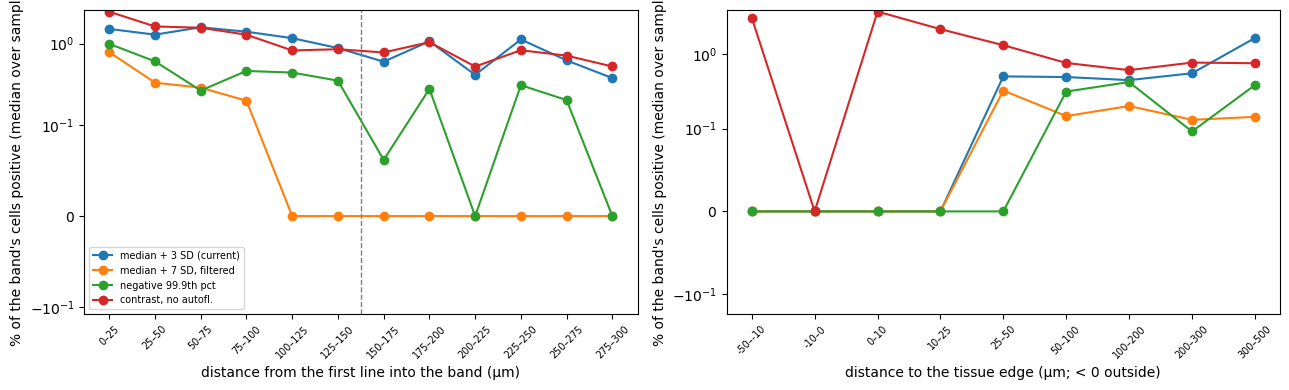

In [9]:
DEPTH_BINS = np.arange(0, 301, 25)
EDGE_BINS = np.array([-50, -10, 0, 10, 25, 50, 100, 200, 300, 500])
profiles = []
for name, df in cells.items():
    if "in first" not in df:
        continue
    inside = df["in first"].to_numpy()
    for key, values, bins in (("depth", df["from first (um)"].to_numpy(), DEPTH_BINS),
                              ("edge", df["edge (um)"].to_numpy(), EDGE_BINS)):
        which = np.digitize(values, bins)
        for rule in RULES:
            positive = calls[name, "first", rule]
            for b in range(1, len(bins)):
                sel = inside & (which == b)
                if sel.sum() >= 20:
                    profiles.append({"name": name, "key": key, "rule": SHORT[rule], "bin": b,
                                     "% positive": 100 * positive[sel].mean()})
profiles = pd.DataFrame(profiles)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, key, bins, xlabel in ((axes[0], "depth", DEPTH_BINS, "distance from the first line into the band (µm)"),
                              (axes[1], "edge", EDGE_BINS, "distance to the tissue edge (µm; < 0 outside)")):
    if not len(profiles):
        continue
    for rule in SHORT.values():
        m = profiles[(profiles["key"] == key) & (profiles["rule"] == rule)].groupby("bin")["% positive"].median()
        ax.plot(np.arange(len(bins) - 1)[m.index - 1], m.values, marker="o", label=rule)
    ax.set_xticks(range(len(bins) - 1), [f"{bins[i]:g}–{bins[i + 1]:g}" for i in range(len(bins) - 1)],
                  rotation=45, fontsize=7)
    ax.set_xlabel(xlabel); ax.set_ylabel("% of the band's cells positive (median over samples)")
    ax.set_yscale("symlog", linthresh=0.1)
axes[0].axvline((DEPTH_UM / 25) - 0.5, color="grey", lw=1, ls="--")
axes[0].legend(fontsize=7)
plt.tight_layout()

## 5. Does the genotype comparison change with the band?

Positives per mm of junction, per sample, compared between genotypes with `C.compare_groups` (two genotypes: Mann-Whitney U, two-sided; more than two: Kruskal-Wallis, and no ratio): on samples, and on slide means (the safer unit: sections of one slide may be one assembloid). The **ratio** is the second genotype's median over the first's (alphabetical order, printed above the table; the two medians per sample are shown too); it is infinite where the first genotype's median is 0. The question is not whether p is small — with these numbers it rarely will be — but whether the **ratio and p move when only the band changes**. To keep it a pure band effect, the main table uses only the samples that have all three bands; the second table uses every sample that has the band in question.

In [10]:
def genotype_table(frame):
    rows = []
    for (band, rule), g in frame.groupby(["band", "rule"], sort=False):
        row = {"band": band, "rule": SHORT[rule]}
        for unit in ("sample", "slide"):
            r = C.compare_groups(g, ["per mm"], unit=unit).iloc[0]
            ratio = [c for c in r.index if " / " in c]
            if unit == "sample":
                row.update({c: r[c] for c in r.index if c.endswith(" median")})
            row[f"n ({unit})"] = r["n"]
            row[f"ratio ({unit})"] = r[ratio[0]] if ratio else np.nan
            row[f"p ({unit})"] = r.get("p", r.get("Mann-Whitney p", np.nan))
            row["test"] = r.get("test", "Mann-Whitney")
        rows.append(row)
    return pd.DataFrame(rows).set_index(["rule", "band"]).sort_index(level=0, sort_remaining=False)


groups = sorted(meta["Genotype"].dropna().unique())
print("ratio is", " / ".join(groups[:2][::-1]) if len(groups) == 2 else "not given (needs exactly two genotypes)")
all_bands = [n for n in cells if all(b in meta.loc[n, "bands"] for b in C.BANDS)]
common = counts[counts["name"].isin(all_bands)]
print(f"samples with all three bands: {len(all_bands)}")
order = pd.MultiIndex.from_product([list(SHORT.values()), list(C.BANDS)])
display(tidy(genotype_table(common).reindex(order).dropna(how="all")) if len(common) else "none")
print("every sample with that band:")
display(tidy(genotype_table(counts).reindex(order).dropna(how="all")))

ratio is WT3 / GD1
samples with all three bands: 25


GD1 median  WT3 median n (sample)  ratio (sample) p (sample)          test n (slide)  ratio (slide) p (slide)
median + 3 SD (current) first           80.71       93.98   14 vs 11            1.16    9.3e-01  Mann-Whitney    9 vs 8           1.44   8.1e-01
                        second          81.16       92.37   14 vs 11            1.14    9.8e-01  Mann-Whitney    9 vs 8           1.26   9.6e-01
                        automatic       98.63      179.27   14 vs 11            1.82    5.7e-01  Mann-Whitney    9 vs 8           1.81   6.7e-01
median + 7 SD, filtered first            6.61       24.10   14 vs 11            3.64    3.4e-03  Mann-Whitney    9 vs 8           2.49   5.9e-02
                        second           6.39       25.09   14 vs 11            3.93    1.1e-02  Mann-Whitney    9 vs 8           2.30   1.4e-01
                        automatic        7.67       44.03   14 vs 11            5.74    1.1e-02  Mann-Whitney    9 vs 8           4.07   1.7e-01
negative 99.9th pct     first           38.77       27.82   14 vs 11            0.72    8.5e-01  Mann-Whitney    9 vs 8           0.43   4.2e-01
                        second          61.49       26.00   14 vs 11            0.42    6.4e-01  Mann-Whitney    9 vs 8           0.44   4.8e-01
                        automatic       88.76       28.54   14 vs 11            0.32    6.0e-01  Mann-Whitney    9 vs 8           0.31   4.8e-01
contrast, no autofl.    first           38.62       91.37   14 vs 11            2.37    7.9e-03  Mann-Whitney    9 vs 8           1.77   3.6e-02
                        second          39.85       86.27   14 vs 11            2.16    4.0e-02  Mann-Whitney    9 vs 8           1.77   2.8e-01
                        automatic       46.38      176.13   14 vs 11            3.80    2.7e-02  Mann-Whitney    9 vs 8           2.84   2.4e-01

every sample with that band:


GD1 median  WT3 median n (sample)  ratio (sample) p (sample)          test n (slide)  ratio (slide) p (slide)
median + 3 SD (current) first           66.94       93.98   19 vs 11            1.40    5.5e-01  Mann-Whitney   11 vs 8           1.44   7.2e-01
                        second          81.16       92.37   16 vs 11            1.14    9.4e-01  Mann-Whitney    9 vs 8           0.75   8.1e-01
                        automatic      118.76      179.27   15 vs 11            1.51    5.3e-01  Mann-Whitney   10 vs 8           1.59   6.3e-01
median + 7 SD, filtered first            5.99       24.10   19 vs 11            4.02    1.4e-03  Mann-Whitney   11 vs 8           2.66   2.0e-02
                        second           6.39       25.09   16 vs 11            3.93    9.6e-03  Mann-Whitney    9 vs 8           2.30   9.3e-02
                        automatic        8.05       44.03   15 vs 11            5.47    2.2e-02  Mann-Whitney   10 vs 8           3.71   2.7e-01
negative 99.9th pct     first           22.98       27.82   19 vs 11            1.21    5.8e-01  Mann-Whitney   11 vs 8           0.48   6.6e-01
                        second          45.78       26.00   16 vs 11            0.57    1.0e+00  Mann-Whitney    9 vs 8           0.51   6.1e-01
                        automatic       80.95       28.54   15 vs 11            0.35    6.8e-01  Mann-Whitney   10 vs 8           0.45   5.1e-01
contrast, no autofl.    first           28.40       91.37   19 vs 11            3.22    3.4e-03  Mann-Whitney   11 vs 8           2.68   9.1e-03
                        second          33.27       86.27   16 vs 11            2.59    2.8e-02  Mann-Whitney    9 vs 8           2.07   2.0e-01
                        automatic       53.51      176.13   15 vs 11            3.29    2.6e-02  Mann-Whitney   10 vs 8           2.76   2.4e-01

### What it showed (21 October 2026: 30 samples; second band on 27, automatic on 26)

**The bands share most of their cells**: median Jaccard 0.92 first–second, 0.81 first–automatic, 0.87 second–automatic. The exceptions are the finder's failures (`033-032_s12`, `041-040_s1`: 0.01) and two samples where the annotators disagree (`037-036_s25` 0.39, `041-040_s1` 0.56) — all Damaged.

**% positive barely depends on whose band**, for the calibrated rule: second − first within ±0.9 pp, automatic − first within ±0.5 pp (CCC 0.90). On the samples triage keeps, automatic vs first CCC 0.91 (calibrated) and 0.92 (current). Per mm is less stable for the automatic band: where the finder's line is much shorter than the hand-drawn one (down to 6 % of its length in `052-051_s18`), dividing by it inflates the count — **normalise by the band's area or by the hand-drawn length, not by the finder's line**.

**Depth.** Within the first band, 75 % of the calibrated rule's positives are in the first 150 µm, which holds 47 % of the cells; a 150 µm band would keep the ranking of samples (Spearman 0.95 with 300 µm). Positives within 10 µm of the tissue edge are few (8 % of the calibrated rule's), but 33 lie past the outline — the rim the band extends over is worth keeping.

**Genotype by band** (calibrated rule, all samples with that band): first 4.0× (p 0.001; slides p 0.020), second 3.9× (p 0.010; slides 0.093), automatic 5.5× (p 0.022; slides 0.27). **Same direction and size whichever band is used**; the slide-level p rises with fewer slides (second, automatic lack the routed samples). The current rule finds nothing with any band.